# CME519 Data Mining — Midterm Project
## Notebook 2 — Data Preparation, Feature Engineering & Feature Selection

**Student:** Musa AL AHMED (26221001014) · **Dataset:** AIDev (hao-li/AIDev)

CRISP-DM phase 3 (data preparation). Input: `data/pr_level.parquet` from Notebook 1.

**Order of operations (to avoid data leakage):**

1. Row-wise feature engineering (each new value uses only its own row → safe before the split).
2. **Train/test split (80/20, stratified).** The test set is locked away until the final evaluation in Notebook 3.
3. Every step that *learns* something from the data (imputation values, outlier caps, rare-category groups, scaling parameters, selected features) is fitted on the **training set only**, inside a scikit-learn `Pipeline`.
4. Comparison of outlier treatments, scaling and **feature-selection methods** with 5-fold stratified cross-validation.

**Evaluation focus.** The business goal is to flag PRs that are likely to be **rejected** (the minority class). Besides ROC-AUC, the main metric is **PR-AUC of the rejected class** (average precision with "not merged" as the positive class).

## 1. Setup

In [ ]:
import os, sys, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, RobustScaler, FunctionTransformer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import (VarianceThreshold, SelectKBest, mutual_info_classif, RFE,
                                       SequentialFeatureSelector, SelectFromModel)
from sklearn.metrics import average_precision_score, roc_auc_score, recall_score, precision_score, f1_score

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 80); pd.set_option("display.width", 170)
sns.set_theme(style="whitegrid")

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK_DIR = "/content/drive/MyDrive/CME519_AIDev"
else:
    WORK_DIR = os.environ.get("AIDEV_WORK_DIR", os.path.abspath("CME519_AIDev"))
DATA_DIR = os.path.join(WORK_DIR, "data"); FIG_DIR = os.path.join(WORK_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    p = os.path.join(FIG_DIR, f"{name}.png"); plt.savefig(p, dpi=150, bbox_inches="tight"); print("figure saved ->", p)

df = pd.read_parquet(os.path.join(DATA_DIR, "pr_level.parquet"))
print(f"Loaded PR-level data: {df.shape[0]:,} rows x {df.shape[1]} columns")
print("Target share (merged=1):", round(df["merged"].mean(), 4))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded PR-level data: 332,406 rows x 37 columns
Target share (merged=1): 0.7424


## 2. Row-wise feature engineering

These features are computed from a single row only, so creating them before the split does not leak information between training and test data.

| Group | New features |
|---|---|
| Date (`created_at`) | `created_hour`, `created_weekday`, `is_weekend`, `created_month` |
| Author | `user_account_age_days` (account age when the PR was opened) |
| Text | `title_len`, `title_words`, `body_len`, `has_body`, `title_type` (feat / fix / docs / …), `body_has_checklist`, `body_mentions_test` |
| Code change | `net_lines`, `lines_per_file`, `test_file_ratio`, `doc_file_ratio`, `config_file_ratio` |
| Repository | `repo_has_license` |

After engineering, the raw `created_at`, `user_created_at`, `title` and `body` columns are dropped — the model cannot use dates or free text directly.

In [ ]:
fe = df.copy()
created = pd.to_datetime(fe["created_at"], utc=True, errors="coerce")
fe["created_hour"] = created.dt.hour
fe["created_weekday"] = created.dt.dayofweek          # 0 = Monday
fe["is_weekend"] = (fe["created_weekday"] >= 5).astype("int8")
fe["created_month"] = created.dt.month
if "user_created_at" in fe:
    ucreated = pd.to_datetime(fe["user_created_at"], utc=True, errors="coerce")
    fe["user_account_age_days"] = (created - ucreated).dt.days.clip(lower=0)

title = fe["title"].fillna(""); body = fe["body"].fillna("")
fe["title_len"] = title.str.len()
fe["title_words"] = title.str.split().str.len()
fe["body_len"] = body.str.len()
fe["has_body"] = body.str.strip().ne("").astype("int8")
fe["title_type"] = title.str.lower().str.extract(
    r"^\s*(feat|fix|docs?|chore|refactor|tests?|ci|build|perf|style)\b", expand=False).fillna("other")
fe["title_type"] = fe["title_type"].replace({"doc": "docs", "tests": "test"})
fe["body_has_checklist"] = body.str.contains(r"- \[[ xX]\]", regex=True).astype("int8")
fe["body_mentions_test"] = body.str.lower().str.contains(r"\btest", regex=True).astype("int8")

nfc = fe["n_file_changes"].replace(0, np.nan)
fe["net_lines"] = fe["additions"] - fe["deletions"]
fe["lines_per_file"] = fe["changes"] / nfc
fe["test_file_ratio"] = fe["n_test_files"] / nfc
fe["doc_file_ratio"] = fe["n_doc_files"] / nfc
fe["config_file_ratio"] = fe["n_config_files"] / nfc
fe["repo_has_license"] = fe["repo_license"].notna().astype("int8")
fe["repo_is_forked"] = fe["repo_is_forked"].map({True: "yes", False: "no"})

ENGINEERED = ["created_hour", "created_weekday", "is_weekend", "created_month", "user_account_age_days",
              "title_len", "title_words", "body_len", "has_body", "title_type", "body_has_checklist",
              "body_mentions_test", "net_lines", "lines_per_file", "test_file_ratio", "doc_file_ratio",
              "config_file_ratio", "repo_has_license"]
ENGINEERED = [c for c in ENGINEERED if c in fe.columns]
display(fe[ENGINEERED].describe(include="all").T.head(25))
print(f"{len(ENGINEERED)} engineered features created.")

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
created_hour,332406.0,NaN,NaN,NaN,12.153132,6.67718,0.0,7.0,13.0,18.0,23.0
created_weekday,332406.0,NaN,NaN,NaN,2.755573,1.927058,0.0,1.0,3.0,4.0,6.0
is_weekend,332406.0,NaN,NaN,NaN,0.221347,0.415154,0.0,0.0,0.0,0.0,1.0
created_month,332406.0,NaN,NaN,NaN,5.141778,3.720745,1.0,2.0,3.0,8.0,12.0
user_account_age_days,241520.0,NaN,NaN,NaN,3581.480267,1855.896751,0.0,2105.0,4084.0,5009.0,6642.0
title_len,332406.0,NaN,NaN,NaN,55.618797,17.745634,1.0,44.0,56.0,67.0,558.0
title_words,332406.0,NaN,NaN,NaN,7.631201,2.479398,1.0,6.0,8.0,9.0,65.0
body_len,332406.0,NaN,NaN,NaN,1832.224602,3055.897802,0.0,622.0,1230.0,2225.0,216211.0
has_body,332406.0,NaN,NaN,NaN,0.995075,0.070003,0.0,1.0,1.0,1.0,1.0
title_type,332406,11,other,158489,NaN,NaN,NaN,NaN,NaN,NaN,NaN


18 engineered features created.


figure saved -> /content/drive/MyDrive/CME519_AIDev/figures/11_engineered_features_vs_target.png


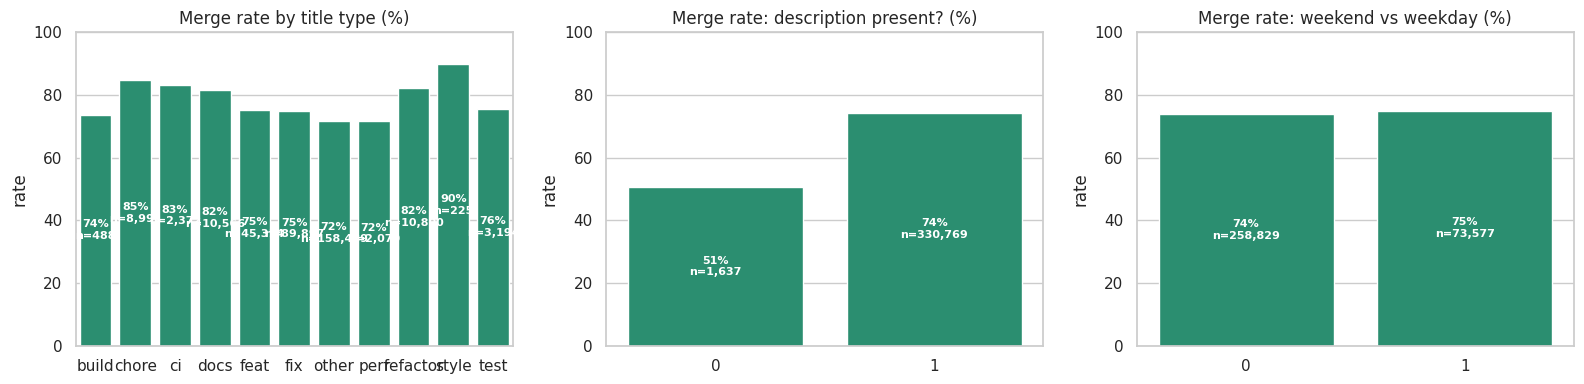

Interpretation: engineered features whose merge rate differs from the overall rate (74.2%) add information that the raw columns did not show directly.


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (col, title) in zip(axes, [("title_type", "Merge rate by title type"),
                                   ("has_body", "Merge rate: description present?"),
                                   ("is_weekend", "Merge rate: weekend vs weekday")]):
    r = fe.groupby(col)["merged"].agg(rate="mean", n="size")
    sns.barplot(x=r.index.astype(str), y=r["rate"] * 100, ax=ax, color="#1b9e77")
    ax.set_title(title + " (%)"); ax.set_xlabel(""); ax.set_ylim(0, 100)
    for i, (v, n) in enumerate(zip(r["rate"] * 100, r["n"])):
        ax.text(i, v / 2, f"{v:.0f}%\nn={n:,}", ha="center", va="center", color="white", fontsize=8, fontweight="bold")
plt.tight_layout(); save_fig("11_engineered_features_vs_target"); plt.show()
print("Interpretation: engineered features whose merge rate differs from the overall rate "
      f"({fe['merged'].mean()*100:.1f}%) add information that the raw columns did not show directly.")

## 3. Define model inputs and remove leakage

- **Removed (leakage):** `state`, `closed_at`, `merged_at` — only known after the outcome.
- **Removed (identifiers / raw text / raw dates):** ids, URLs, names, `title`, `body`, `created_at`, `user_created_at`.
- **Kept:** numeric and categorical features listed below.

In [ ]:
LEAKAGE = ["state", "closed_at", "merged_at"]
DROP = LEAKAGE + ["id", "number", "repo_id", "user_id", "user", "repo_full_name", "repo_url", "html_url",
                  "title", "body", "created_at", "user_created_at", "repo_license"]
CAT_FEATURES = [c for c in ["agent", "repo_language", "repo_is_forked", "title_type"] if c in fe]
NUM_FEATURES = [c for c in fe.columns if c not in DROP + CAT_FEATURES + ["merged"]]
COMMIT_FEATURES = [c for c in ["n_commits", "n_file_changes", "additions", "deletions", "changes", "max_file_changes",
                               "n_test_files", "n_doc_files", "n_config_files", "n_added_files", "n_removed_files",
                               "n_renamed_files", "n_distinct_ext", "net_lines", "lines_per_file", "test_file_ratio",
                               "doc_file_ratio", "config_file_ratio"] if c in NUM_FEATURES]

X = fe[NUM_FEATURES + CAT_FEATURES].copy()
y = fe["merged"].astype(int)
for c in NUM_FEATURES:
    X[c] = pd.to_numeric(X[c], errors="coerce").astype("float64")
for c in CAT_FEATURES:
    X[c] = X[c].astype("object").where(X[c].notna(), np.nan)

print(f"Model input: {X.shape[1]} features = {len(NUM_FEATURES)} numeric + {len(CAT_FEATURES)} categorical")
print("Numeric    :", NUM_FEATURES)
print("Categorical:", CAT_FEATURES, "| unique values:", X[CAT_FEATURES].nunique().to_dict())
print("Removed leakage columns:", LEAKAGE)

Model input: 38 features = 34 numeric + 4 categorical
Numeric    : ['repo_forks', 'repo_stars', 'user_followers', 'user_following', 'n_commits', 'n_file_changes', 'additions', 'deletions', 'changes', 'n_test_files', 'n_doc_files', 'n_config_files', 'n_added_files', 'n_removed_files', 'n_renamed_files', 'max_file_changes', 'n_distinct_ext', 'created_hour', 'created_weekday', 'is_weekend', 'created_month', 'user_account_age_days', 'title_len', 'title_words', 'body_len', 'has_body', 'body_has_checklist', 'body_mentions_test', 'net_lines', 'lines_per_file', 'test_file_ratio', 'doc_file_ratio', 'config_file_ratio', 'repo_has_license']
Categorical: ['agent', 'repo_language', 'repo_is_forked', 'title_type'] | unique values: {'agent': 6, 'repo_language': 184, 'repo_is_forked': 2, 'title_type': 11}
Removed leakage columns: ['state', 'closed_at', 'merged_at']


## 4. Train / test split — before any fitted preprocessing

80% training, 20% test, **stratified** so both sets keep the same merged/not-merged ratio. All learning (imputation, capping, encoding, scaling, feature selection) happens on the training set only.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
split = pd.DataFrame({"rows": [len(X_train), len(X_test)],
                      "merged_%": [y_train.mean() * 100, y_test.mean() * 100]}, index=["train", "test"]).round(2)
display(split)
print("Interpretation: identical class ratios in train and test confirm the stratified split.")

,rows,merged_%
train,265924,74.24
test,66482,74.24


Interpretation: identical class ratios in train and test confirm the stratified split.


## 5. Missing values — imputation (fitted on train)

- **Numeric:** median (robust to the skewed distributions found in the EDA) **+ missing-indicator columns**, so the model also knows that a value was missing.
- **Categorical:** a constant `"missing"` category.

The median values below are computed on the training set and reused unchanged for the test set.

,train_missing_%,median_from_train
user_followers,27.33,59.0
user_following,27.33,7.0
user_account_age_days,27.33,4081.0
max_file_changes,2.85,79.0
repo_language,0.65,constant 'missing'
n_commits,0.42,2.0
deletions,0.42,17.0
additions,0.42,110.0
n_file_changes,0.42,5.0
changes,0.42,152.0


figure saved -> /content/drive/MyDrive/CME519_AIDev/figures/12_imputation_effect.png


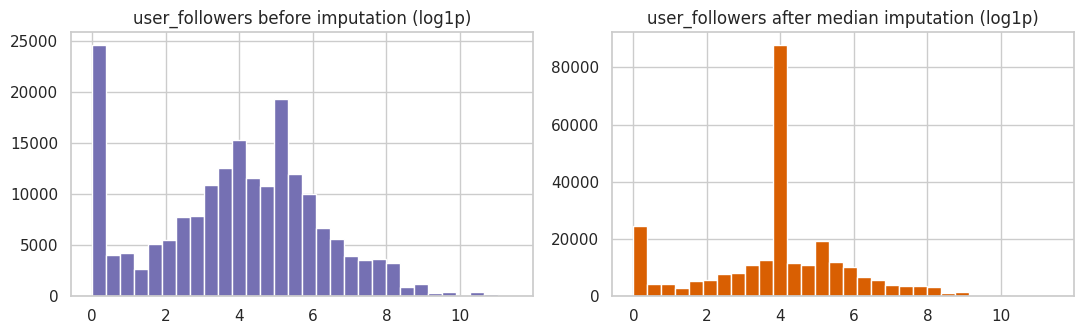

Interpretation: median imputation creates a spike at the median; the missing-indicator column keeps the information that the value was originally missing.


In [ ]:
miss_tr = X_train.isna().mean().mul(100).round(2)
miss_tr = miss_tr[miss_tr > 0].sort_values(ascending=False).to_frame("train_missing_%")
num_imp = SimpleImputer(strategy="median").fit(X_train[NUM_FEATURES])
miss_tr["median_from_train"] = [dict(zip(NUM_FEATURES, num_imp.statistics_)).get(c, "constant 'missing'") for c in miss_tr.index]
display(miss_tr)

c = miss_tr.index[0] if len(miss_tr) else None
if c in NUM_FEATURES:
    before = X_train[c]; after = before.fillna(before.median())
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].hist(np.log1p(before.dropna().clip(lower=0)), bins=30, color="#7570b3"); ax[0].set_title(f"{c} before imputation (log1p)")
    ax[1].hist(np.log1p(after.clip(lower=0)), bins=30, color="#d95f02"); ax[1].set_title(f"{c} after median imputation (log1p)")
    plt.tight_layout(); save_fig("12_imputation_effect"); plt.show()
    print("Interpretation: median imputation creates a spike at the median; the missing-indicator column keeps "
          "the information that the value was originally missing.")

## 6. Outliers — comparison of treatments (fitted on train)

The EDA showed heavy right tails. Large PRs and popular repositories are real, so deleting them would remove valid information. Four strategies are compared on the training data:

1. **Keep as is**
2. **Capping (winsorizing)** at the 1st / 99th percentile of the training data
3. **log1p transform**
4. **log1p + capping**

Skewed numeric features (skew > 1) on train: 25


strategy,skew | cap 1-99%,skew | keep,skew | log1p,skew | log1p + cap
feature,,,,
additions,5.21,201.80,0.18,0.12
changes,5.31,175.41,0.20,0.14
repo_stars,6.45,6.45,0.67,0.67
user_followers,4.80,13.89,-0.11,-0.16


strategy,IQR out% | cap 1-99%,IQR out% | keep,IQR out% | log1p,IQR out% | log1p + cap
feature,,,,
additions,15.69,15.69,0.33,0.0
changes,15.86,15.86,0.48,0.0
repo_stars,16.04,16.04,0.00,0.0
user_followers,13.49,13.49,0.28,0.0


figure saved -> /content/drive/MyDrive/CME519_AIDev/figures/13_outlier_strategies.png


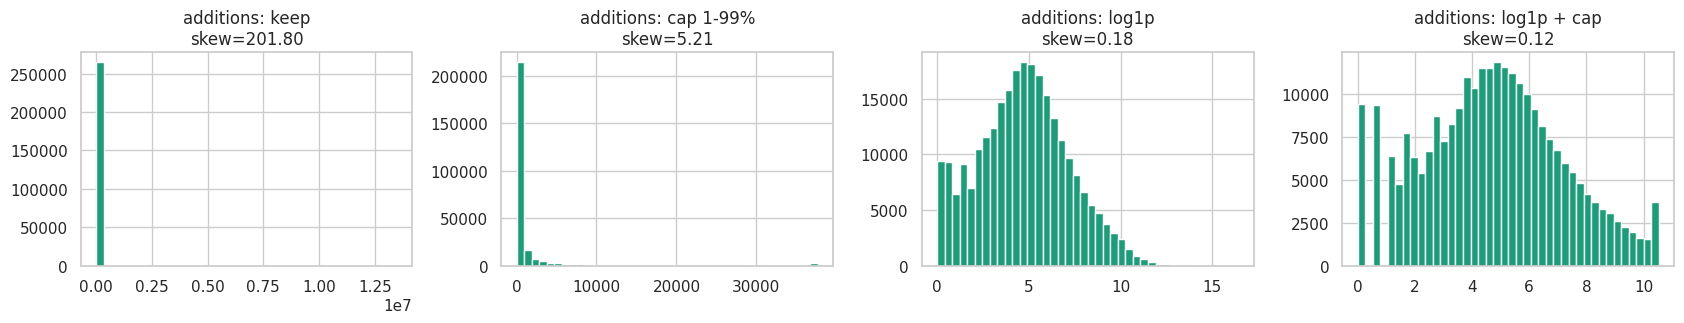

Interpretation: log1p removes most of the skew, and capping limits the influence of the few extreme values. The model-based comparison below decides which strategy is used.


In [ ]:
class QuantileCapper(BaseEstimator, TransformerMixin):
    # Clip each column to [q_low, q_high] learned on the training data.
    def __init__(self, low=0.01, high=0.99):
        self.low, self.high = low, high
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.lo_ = X.quantile(self.low).values; self.hi_ = X.quantile(self.high).values
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)
    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

def signed_log1p(x):
    return np.sign(x) * np.log1p(np.abs(x))

SKEWED = [c for c in NUM_FEATURES if X_train[c].skew() > 1]
print(f"Skewed numeric features (skew > 1) on train: {len(SKEWED)}")

demo_cols = [c for c in ["additions", "changes", "repo_stars", "user_followers"] if c in SKEWED][:4]
rows = []
for c in demo_cols:
    s = X_train[c].dropna()
    cap = s.clip(s.quantile(.01), s.quantile(.99))
    lg = signed_log1p(s); lgc = signed_log1p(cap)
    for name, v in [("keep", s), ("cap 1-99%", cap), ("log1p", lg), ("log1p + cap", lgc)]:
        q1, q3 = v.quantile([.25, .75]); iqr = q3 - q1
        rows.append({"feature": c, "strategy": name, "skew": v.skew(), "std": v.std(),
                     "IQR_outliers_%": ((v < q1 - 1.5 * iqr) | (v > q3 + 1.5 * iqr)).mean() * 100})
out_cmp = pd.DataFrame(rows)
display(out_cmp.pivot(index="feature", columns="strategy", values="skew").round(2).add_prefix("skew | "))
display(out_cmp.pivot(index="feature", columns="strategy", values="IQR_outliers_%").round(2).add_prefix("IQR out% | "))

if demo_cols:
    c = demo_cols[0]; s = X_train[c].dropna()
    fig, axes = plt.subplots(1, 4, figsize=(17, 3.4))
    for ax, (name, v) in zip(axes, [("keep", s), ("cap 1-99%", s.clip(s.quantile(.01), s.quantile(.99))),
                                    ("log1p", signed_log1p(s)), ("log1p + cap", signed_log1p(s.clip(s.quantile(.01), s.quantile(.99))))]):
        ax.hist(v, bins=40, color="#1b9e77"); ax.set_title(f"{c}: {name}\nskew={v.skew():.2f}")
    plt.tight_layout(); save_fig("13_outlier_strategies"); plt.show()
print("Interpretation: log1p removes most of the skew, and capping limits the influence of the few extreme values. "
      "The model-based comparison below decides which strategy is used.")

## 7. Encoding and scaling — the preprocessing pipeline

- **One-hot encoding** for nominal categories (`agent`, `repo_language`, `title_type`, `repo_is_forked`). Integer codes would create a false order (e.g. "Python > Go"). Categories with < 1% frequency in the training data are grouped into one *infrequent* column (`min_frequency=0.01`) to control the number of columns (high-cardinality handling).
- **Scaling** with `StandardScaler` (z-score). Needed for distance-based (KNN) and linear models (Logistic Regression); tree models do not need it.

Everything is wrapped in one `ColumnTransformer`, so it is fitted on the training folds only.

In [ ]:
def make_preprocessor(outlier="log_cap", scaler="standard"):
    steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]
    if outlier in ("cap", "log_cap"):
        steps.append(("cap", QuantileCapper(0.01, 0.99)))
    if outlier in ("log", "log_cap"):
        steps.append(("log", FunctionTransformer(signed_log1p, feature_names_out="one-to-one")))
    if scaler == "standard":
        steps.append(("scale", StandardScaler()))
    elif scaler == "minmax":
        steps.append(("scale", MinMaxScaler()))
    elif scaler == "robust":
        steps.append(("scale", RobustScaler()))
    num_pipe = Pipeline(steps)
    cat_pipe = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="missing")),
                         ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01,
                                                  sparse_output=False))])
    return ColumnTransformer([("num", num_pipe, NUM_FEATURES), ("cat", cat_pipe, CAT_FEATURES)],
                             verbose_feature_names_out=False)

pre = make_preprocessor().fit(X_train)
feat_names = pre.get_feature_names_out()
Xt_train = pd.DataFrame(pre.transform(X_train), columns=feat_names, index=X_train.index)
print(f"After preprocessing: {Xt_train.shape[1]} columns "
      f"({len(NUM_FEATURES)} numeric + missing indicators + one-hot columns)")
display(Xt_train.describe().T[["mean", "std", "min", "max"]].head(15).round(3))
print("Interpretation: numeric columns now have mean ~0 and std ~1, so no feature dominates distances in KNN.")

After preprocessing: 86 columns (34 numeric + missing indicators + one-hot columns)


,mean,std,min,max
repo_forks,0.0,1.0,-1.720,2.913
repo_stars,-0.0,1.0,-1.348,2.847
user_followers,-0.0,1.0,-2.041,2.395
user_following,0.0,1.0,-1.497,2.768
n_commits,0.0,1.0,-0.840,3.723
n_file_changes,0.0,1.0,-1.108,2.996
additions,0.0,1.0,-1.922,2.379
deletions,-0.0,1.0,-1.307,2.664
changes,0.0,1.0,-2.093,2.424
n_test_files,-0.0,1.0,-0.655,3.678


Interpretation: numeric columns now have mean ~0 and std ~1, so no feature dominates distances in KNN.


### 7.1 Does preprocessing matter? (5-fold CV on a training sample)

To keep the comparison fast, a stratified sample of the training set (up to 40,000 PRs) is used. Every configuration is evaluated with the same 5 folds.

In [ ]:
def ap_rejected(est, X, y):
    # PR-AUC where the positive class is 'not merged' (rejected, the minority class)
    p0 = est.predict_proba(X)[:, list(est.classes_).index(0)]
    return average_precision_score((np.asarray(y) == 0).astype(int), p0)
def recall_rejected(est, X, y):
    return recall_score(y, est.predict(X), pos_label=0)
def precision_rejected(est, X, y):
    return precision_score(y, est.predict(X), pos_label=0, zero_division=0)

SCORING = {"pr_auc_rejected": ap_rejected, "roc_auc": "roc_auc", "f1_macro": "f1_macro",
           "recall_rejected": recall_rejected, "precision_rejected": precision_rejected}
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

n_s = min(40_000, len(X_train))
X_s, _, y_s, _ = train_test_split(X_train, y_train, train_size=n_s, stratify=y_train, random_state=RANDOM_STATE) \
    if n_s < len(X_train) else (X_train, None, y_train, None)
print(f"CV sample: {len(X_s):,} PRs, merged = {y_s.mean()*100:.1f}%")

def cv_eval(model, Xd=None, yd=None):
    r = cross_validate(model, X_s if Xd is None else Xd, y_s if yd is None else yd,
                       scoring=SCORING, cv=CV, n_jobs=-1)
    return {k.replace("test_", ""): v.mean() for k, v in r.items() if k.startswith("test_")} | \
           {"pr_auc_std": r["test_pr_auc_rejected"].std(), "fit_time_s": r["fit_time"].mean()}

LR = lambda: LogisticRegression(max_iter=2000, class_weight="balanced")
KNN = lambda: KNeighborsClassifier(n_neighbors=15)

rows = []
for outlier in ["none", "cap", "log", "log_cap"]:
    for name, mdl in [("LogReg", LR), ("KNN(k=15)", KNN)]:
        rows.append({"outliers": outlier, "scaler": "standard", "model": name,
                     **cv_eval(Pipeline([("pre", make_preprocessor(outlier, "standard")), ("clf", mdl())]))})
for scaler in ["none", "minmax", "robust"]:
    rows.append({"outliers": "log_cap", "scaler": scaler, "model": "KNN(k=15)",
                 **cv_eval(Pipeline([("pre", make_preprocessor("log_cap", scaler)), ("clf", KNN())]))})
prep_cmp = pd.DataFrame(rows)
display(prep_cmp.round(4).sort_values(["model", "pr_auc_rejected"], ascending=[True, False]))

best_prep = prep_cmp[prep_cmp["model"] == "LogReg"].sort_values("pr_auc_rejected", ascending=False).iloc[0]
knn_no_scale = prep_cmp.query("model == 'KNN(k=15)' and scaler == 'none'")["pr_auc_rejected"].iloc[0]
knn_std = prep_cmp.query("model == 'KNN(k=15)' and scaler == 'standard' and outliers == 'log_cap'")["pr_auc_rejected"].iloc[0]
BEST_OUTLIER = best_prep["outliers"]
print(f"Interpretation: best outlier treatment for LogReg = '{BEST_OUTLIER}' "
      f"(PR-AUC rejected = {best_prep['pr_auc_rejected']:.4f}). "
      f"KNN without scaling: {knn_no_scale:.4f} vs with StandardScaler: {knn_std:.4f} -> "
      + ("scaling clearly helps the distance-based model." if knn_std > knn_no_scale + 0.005 else
         "on this sample scaling changes KNN only slightly; StandardScaler is kept because it is required for fair distances."))

CV sample: 40,000 PRs, merged = 74.2%


,outliers,scaler,model,pr_auc_rejected,roc_auc,f1_macro,recall_rejected,precision_rejected,pr_auc_std,fit_time_s
8,log_cap,none,KNN(k=15),0.5476,0.7404,0.6442,0.3017,0.6917,0.0064,0.9414
10,log_cap,robust,KNN(k=15),0.5438,0.7427,0.6341,0.2832,0.6885,0.0127,0.9281
5,log,standard,KNN(k=15),0.5434,0.7439,0.6340,0.2812,0.6954,0.0150,0.7349
7,log_cap,standard,KNN(k=15),0.5421,0.7434,0.6312,0.2769,0.6923,0.0147,0.8742
9,log_cap,minmax,KNN(k=15),0.5120,0.7212,0.6101,0.2416,0.6810,0.0087,0.7523
3,cap,standard,KNN(k=15),0.4947,0.6983,0.6038,0.2314,0.6762,0.0119,0.8079
1,none,standard,KNN(k=15),0.4930,0.6947,0.6054,0.2330,0.6812,0.0086,0.8889
4,log,standard,LogReg,0.5773,0.7535,0.6494,0.6631,0.4364,0.0086,2.7450
6,log_cap,standard,LogReg,0.5715,0.7530,0.6490,0.6655,0.4357,0.0084,1.8248
0,none,standard,LogReg,0.5218,0.7077,0.6165,0.6032,0.3998,0.0127,2.5140


Interpretation: best outlier treatment for LogReg = 'log' (PR-AUC rejected = 0.5773). KNN without scaling: 0.5476 vs with StandardScaler: 0.5421 -> on this sample scaling changes KNN only slightly; StandardScaler is kept because it is required for fair distances.


## 8. Feature selection — comparison of methods

After one-hot encoding and missing indicators the number of columns grows (curse of dimensionality). Several selection methods from the course are compared.
| Type | Method |
|---|---|
| — | All features (baseline) |
| Filter | Variance threshold (drop near-constant columns) |
| Filter | Correlation filter (drop one of each pair with \|r\| > 0.90) |
| Filter | Mutual information — top 15 |
| Wrapper | Recursive Feature Elimination (RFE, Logistic Regression) — 15 features |
| Wrapper | Sequential forward selection (Logistic Regression) — 10 features |
| Embedded | L1-regularised (Lasso) Logistic Regression |
| Embedded | Random Forest importance (above-median) |

**How leakage is avoided.** Each selector is fitted on a separate *selection sample* of the training set (15,000 PRs). The chosen columns are then evaluated on a *different* evaluation sample of the training set (40,000 PRs) with 5-fold stratified CV and three models: **Logistic Regression, KNN and Random Forest**. Selection and evaluation data never overlap, and the test set is not used at all. (Fitting wrapper methods inside every CV fold on 300k rows would take hours on Colab.)

In [ ]:
class CorrelationFilter(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=0.90):
        self.threshold = threshold
    def fit(self, X, y=None):
        c = pd.DataFrame(X).corr().abs().fillna(0).values
        upper = np.triu(c, k=1)
        self.keep_ = np.array([not (upper[:, j] > self.threshold).any() for j in range(c.shape[1])])
        return self
    def transform(self, X):
        return np.asarray(X)[:, self.keep_]
    def get_support(self):
        return self.keep_

def mi_score(X, y):
    return mutual_info_classif(X, y, random_state=RANDOM_STATE)

SELECTORS = {
    "All features": None,
    "Filter: variance threshold": VarianceThreshold(threshold=0.01),
    "Filter: correlation |r|>0.90": CorrelationFilter(0.90),
    "Filter: mutual information (top 15)": SelectKBest(mi_score, k=15),
    "Wrapper: RFE-LogReg (15)": RFE(LogisticRegression(max_iter=2000, class_weight="balanced"), n_features_to_select=15, step=3),
    "Wrapper: forward selection (10)": SequentialFeatureSelector(LogisticRegression(max_iter=1000, class_weight="balanced"),
                                                                 n_features_to_select=10, direction="forward",
                                                                 scoring="roc_auc", cv=3, n_jobs=-1),
    "Embedded: L1 LogReg": SelectFromModel(LogisticRegression(penalty="l1", solver="liblinear", C=0.05,
                                                              class_weight="balanced", max_iter=2000)),
    "Embedded: RandomForest importance": SelectFromModel(RandomForestClassifier(n_estimators=100, max_depth=10, n_jobs=-1,
                                                                                random_state=RANDOM_STATE), threshold="median"),
}
MODELS = {"LogReg": LR, "KNN(k=15)": KNN,
          "RandomForest": lambda: RandomForestClassifier(n_estimators=200, max_depth=14, min_samples_leaf=5,
                                                         class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE)}

# selection sample: disjoint from the CV evaluation sample X_s
rest_idx = X_train.index.difference(X_s.index)
n_sel = min(15_000, len(rest_idx)) if len(rest_idx) > 0 else 0
if n_sel >= 1000:
    X_sel, _, y_sel, _ = train_test_split(X_train.loc[rest_idx], y_train.loc[rest_idx], train_size=n_sel,
                                          stratify=y_train.loc[rest_idx], random_state=RANDOM_STATE) \
        if n_sel < len(rest_idx) else (X_train.loc[rest_idx], None, y_train.loc[rest_idx], None)
else:   # tiny datasets: fall back to the CV sample itself
    X_sel, y_sel = X_s, y_s
print(f"Selection sample: {len(X_sel):,} PRs (disjoint from the {len(X_s):,}-PR evaluation sample)")

pre_sel = make_preprocessor(BEST_OUTLIER).fit(X_sel)
Xsel_t = pd.DataFrame(pre_sel.transform(X_sel), columns=pre_sel.get_feature_names_out())
from sklearn.base import clone
selected = {}
for name, sel in SELECTORS.items():
    t0 = time.time()
    if sel is None:
        selected[name] = list(Xsel_t.columns)
    else:
        sfit = clone(sel).fit(Xsel_t.values, y_sel.values)
        selected[name] = list(Xsel_t.columns[sfit.get_support()])
    print(f"{name:<40} -> {len(selected[name]):>3} features ({time.time()-t0:.0f}s)")

Selection sample: 15,000 PRs (disjoint from the 40,000-PR evaluation sample)
All features                             ->  86 features (0s)
Filter: variance threshold               ->  84 features (0s)
Filter: correlation |r|>0.90             ->  63 features (1s)
Filter: mutual information (top 15)      ->  15 features (6s)
Wrapper: RFE-LogReg (15)                 ->  15 features (12s)
Wrapper: forward selection (10)          ->  10 features (72s)
Embedded: L1 LogReg                      ->  64 features (1s)
Embedded: RandomForest importance        ->  43 features (2s)


In [ ]:
class NameSelector(BaseEstimator, TransformerMixin):
    # keep the given columns (by name) of the preprocessed DataFrame
    def __init__(self, columns=None):
        self.columns = columns
    def fit(self, X, y=None):
        self.cols_ = [c for c in self.columns if c in X.columns]
        return self
    def transform(self, X):
        return X.reindex(columns=self.cols_, fill_value=0.0).values

def pipe_with(cols, model):
    pre = make_preprocessor(BEST_OUTLIER).set_output(transform="pandas")
    return Pipeline([("pre", pre), ("select", NameSelector(cols)), ("clf", model)])

rows = []
t_all = time.time()
for sname, cols in selected.items():
    for mname, mdl in MODELS.items():
        t0 = time.time()
        res = cv_eval(pipe_with(cols, mdl()))
        rows.append({"method": sname, "n_features": len(cols), "model": mname, **res})
        print(f"{sname:<40} {mname:<13} PR-AUC(rej)={res['pr_auc_rejected']:.4f}  ROC-AUC={res['roc_auc']:.4f}  ({time.time()-t0:.0f}s)")
fs_cmp = pd.DataFrame(rows)
print(f"total time: {(time.time()-t_all)/60:.1f} min")

All features                             LogReg        PR-AUC(rej)=0.5773  ROC-AUC=0.7535  (7s)
All features                             KNN(k=15)     PR-AUC(rej)=0.5432  ROC-AUC=0.7439  (77s)
All features                             RandomForest  PR-AUC(rej)=0.6237  ROC-AUC=0.7840  (80s)
Filter: variance threshold               LogReg        PR-AUC(rej)=0.5774  ROC-AUC=0.7536  (8s)
Filter: variance threshold               KNN(k=15)     PR-AUC(rej)=0.5431  ROC-AUC=0.7438  (75s)
Filter: variance threshold               RandomForest  PR-AUC(rej)=0.6250  ROC-AUC=0.7851  (79s)
Filter: correlation |r|>0.90             LogReg        PR-AUC(rej)=0.5771  ROC-AUC=0.7533  (5s)
Filter: correlation |r|>0.90             KNN(k=15)     PR-AUC(rej)=0.5382  ROC-AUC=0.7405  (68s)
Filter: correlation |r|>0.90             RandomForest  PR-AUC(rej)=0.6228  ROC-AUC=0.7839  (70s)
Filter: mutual information (top 15)      LogReg        PR-AUC(rej)=0.5456  ROC-AUC=0.7345  (3s)
Filter: mutual information (top 15

Feature-selection comparison — PR-AUC of the rejected class, 5-fold stratified CV (higher is better)


,model,KNN(k=15),LogReg,RandomForest,mean
method,n_features,,,,
Embedded: L1 LogReg,64,0.5483,0.5758,0.6305,0.5849
Filter: variance threshold,84,0.5431,0.5774,0.6250,0.5818
All features,86,0.5432,0.5773,0.6237,0.5814
Filter: correlation |r|>0.90,63,0.5382,0.5771,0.6228,0.5794
Embedded: RandomForest importance,43,0.5428,0.5679,0.6248,0.5785
Wrapper: forward selection (10),10,0.5356,0.5566,0.6025,0.5649
Filter: mutual information (top 15),15,0.5276,0.5456,0.5968,0.5567
Wrapper: RFE-LogReg (15),15,0.5268,0.5439,0.5840,0.5516


Same comparison — ROC-AUC


model,KNN(k=15),LogReg,RandomForest
method,,,
All features,0.7439,0.7535,0.7840
Embedded: L1 LogReg,0.7451,0.7527,0.7889
Embedded: RandomForest importance,0.7401,0.7497,0.7847
Filter: correlation |r|>0.90,0.7405,0.7533,0.7839
Filter: mutual information (top 15),0.7286,0.7345,0.7676
Filter: variance threshold,0.7438,0.7536,0.7851
Wrapper: RFE-LogReg (15),0.7301,0.7386,0.7610
Wrapper: forward selection (10),0.7328,0.7429,0.7716


figure saved -> /content/drive/MyDrive/CME519_AIDev/figures/14_feature_selection_comparison.png


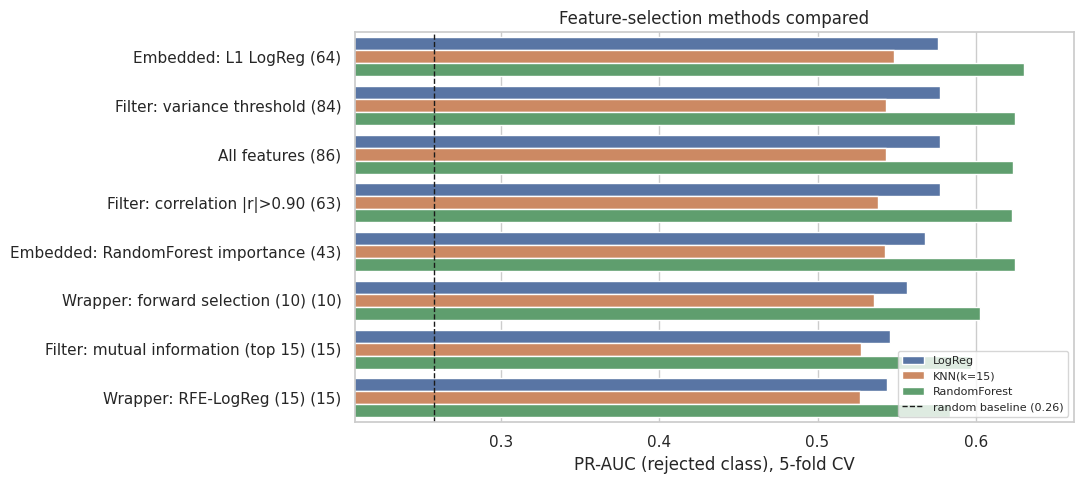

Interpretation: best average PR-AUC with 'Embedded: L1 LogReg' (64 features). The random baseline for PR-AUC equals the share of rejected PRs (0.258); 8 of 8 methods are above it on average. Methods with far fewer features but similar scores are preferred (simpler, faster, less overfitting).


In [ ]:
fs_table = fs_cmp.pivot_table(index=["method", "n_features"], columns="model", values="pr_auc_rejected").round(4)
fs_table["mean"] = fs_table.mean(axis=1).round(4)
fs_table = fs_table.sort_values("mean", ascending=False)
print("Feature-selection comparison — PR-AUC of the rejected class, 5-fold stratified CV (higher is better)")
display(fs_table)
roc_table = fs_cmp.pivot_table(index="method", columns="model", values="roc_auc").round(4)
print("Same comparison — ROC-AUC")
display(roc_table)

fig, ax = plt.subplots(figsize=(11, 5))
plot_df = fs_cmp.copy(); plot_df["method"] = plot_df["method"] + " (" + plot_df["n_features"].astype(str) + ")"
order = fs_table.reset_index().assign(m=lambda d: d["method"] + " (" + d["n_features"].astype(str) + ")")["m"]
sns.barplot(data=plot_df, y="method", x="pr_auc_rejected", hue="model", order=order, ax=ax)
base = 1 - y_s.mean()
ax.axvline(base, ls="--", c="k", lw=1, label=f"random baseline ({base:.2f})")
ax.set_xlabel("PR-AUC (rejected class), 5-fold CV"); ax.set_ylabel(""); ax.legend(loc="lower right", fontsize=8)
ax.set_xlim(max(0, base - 0.05), None)
ax.set_title("Feature-selection methods compared")
plt.tight_layout(); save_fig("14_feature_selection_comparison"); plt.show()

BEST_FS = fs_table.index[0][0]
print(f"Interpretation: best average PR-AUC with '{BEST_FS}' ({len(selected[BEST_FS])} features). "
      f"The random baseline for PR-AUC equals the share of rejected PRs ({base:.3f}); "
      f"{(fs_table['mean'] > base).sum()} of {len(fs_table)} methods are above it on average. "
      "Methods with far fewer features but similar scores are preferred (simpler, faster, less overfitting).")

In [ ]:
# features chosen by several methods = robust signal
votes = pd.Series(0, index=Xsel_t.columns, dtype=int)
for name, cols in selected.items():
    if name != "All features":
        votes[cols] += 1
top_votes = votes.sort_values(ascending=False).head(20).to_frame("selected_by_n_methods")
display(top_votes)
print("Interpretation: features selected by most methods are the most reliable predictors; "
      "they will be discussed in the report and checked again with permutation importance in Notebook 3.")

,selected_by_n_methods
repo_forks,7
user_followers,7
missingindicator_max_file_changes,7
lines_per_file,7
user_following,6
agent_OpenAI_Codex,6
agent_Claude_Code,6
body_len,5
agent_Devin,5
missingindicator_user_followers,5


Interpretation: features selected by most methods are the most reliable predictors; they will be discussed in the report and checked again with permutation importance in Notebook 3.


## 9. Save outputs for Notebook 3

- `data/model_data.parquet` — engineered features + target + `split` column (train / test).
- `data/prep_config.json` — feature lists, chosen outlier strategy, best feature-selection method and its selected columns.
- `data/fs_comparison.csv`, `data/preprocessing_comparison.csv` — tables for the report.

In [ ]:
out = X.copy(); out["merged"] = y
out["split"] = "train"; out.loc[X_test.index, "split"] = "test"
out.to_parquet(os.path.join(DATA_DIR, "model_data.parquet"))
cfg = {"NUM_FEATURES": NUM_FEATURES, "CAT_FEATURES": CAT_FEATURES, "COMMIT_FEATURES": COMMIT_FEATURES,
       "BEST_OUTLIER": BEST_OUTLIER, "BEST_FS": BEST_FS, "BEST_FS_COLUMNS": selected[BEST_FS],
       "RANDOM_STATE": RANDOM_STATE}
with open(os.path.join(DATA_DIR, "prep_config.json"), "w") as f:
    json.dump(cfg, f, indent=2)
fs_cmp.to_csv(os.path.join(DATA_DIR, "fs_comparison.csv"), index=False)
prep_cmp.to_csv(os.path.join(DATA_DIR, "preprocessing_comparison.csv"), index=False)
print("Saved model_data.parquet, prep_config.json, fs_comparison.csv, preprocessing_comparison.csv in", DATA_DIR)
print(f"Train rows: {(out['split']=='train').sum():,} | Test rows: {(out['split']=='test').sum():,}")
print(f"Chosen outlier strategy: {BEST_OUTLIER} | Chosen feature-selection method: {BEST_FS}")

Saved model_data.parquet, prep_config.json, fs_comparison.csv, preprocessing_comparison.csv in /content/drive/MyDrive/CME519_AIDev/data
Train rows: 265,924 | Test rows: 66,482
Chosen outlier strategy: log | Chosen feature-selection method: Embedded: L1 LogReg
